In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
from scipy import stats


In [2]:
dfr = pd.read_csv('Rent (Cleaned).csv')
dfs = pd.read_csv('Sell (Cleaned).csv')

In [3]:
dfr.shape

(18917, 17)

In [4]:
dfs.shape

(18350, 21)

In [5]:
dfr.head()

,property_type,title,price_egp,city,town,district,lat,lon,bedrooms,bathrooms,area_value,furnished,listing_level,listed_date,description,agent_id,broker_id
0,Apartment,First use semi furnished 2BR in El Patio Oro,35000.0,Cairo,New Cairo City,The 5th Settlement,30.025003,31.594761,2,2,128.0,PARTLY,premium,2026-03-04 21:13:08+00:00,Apartment with kitchen and air conditioning fo...,55901,5389
1,Apartment,"Unfurnished apartment for rent with kitchen, a...",50000.0,Cairo,New Cairo City,El Banafseg,30.046291,31.473789,3,3,300.0,NO,premium,2026-03-04 12:47:53+00:00,E14755 Unfurnished apartment for rent with kit...,66449,2520
2,Apartment,Furnished apartment for rent in Al Yasmin 2 Vi...,45000.0,Cairo,New Cairo City,El Yasmeen,30.048929,31.447016,3,3,210.0,YES,premium,2026-03-04 11:12:17+00:00,E14748 Furnished apartment for rent in Al Yasm...,66449,2520
3,Apartment,Unfurnished apartment for rent with air condit...,25000.0,Cairo,New Cairo City,Abou El Houl,29.982248,31.468801,2,2,150.0,NO,premium,2026-03-04 10:58:28+00:00,E14745 Unfurnished apartment for rent with air...,50635,2520
4,Apartment,Furnished apartment for rent behind Mirage Cit...,40000.0,Cairo,New Cairo City,The 1st Settlement,30.052275,31.444633,2,2,130.0,YES,premium,2026-03-04 09:19:33+00:00,E12494B Furnished apartment for rent behind Mi...,44158,2520


In [6]:
dfr.head()

,property_type,title,price_egp,city,town,district,lat,lon,bedrooms,bathrooms,area_value,furnished,listing_level,listed_date,description,agent_id,broker_id
0,Apartment,First use semi furnished 2BR in El Patio Oro,35000.0,Cairo,New Cairo City,The 5th Settlement,30.025003,31.594761,2,2,128.0,PARTLY,premium,2026-03-04 21:13:08+00:00,Apartment with kitchen and air conditioning fo...,55901,5389
1,Apartment,"Unfurnished apartment for rent with kitchen, a...",50000.0,Cairo,New Cairo City,El Banafseg,30.046291,31.473789,3,3,300.0,NO,premium,2026-03-04 12:47:53+00:00,E14755 Unfurnished apartment for rent with kit...,66449,2520
2,Apartment,Furnished apartment for rent in Al Yasmin 2 Vi...,45000.0,Cairo,New Cairo City,El Yasmeen,30.048929,31.447016,3,3,210.0,YES,premium,2026-03-04 11:12:17+00:00,E14748 Furnished apartment for rent in Al Yasm...,66449,2520
3,Apartment,Unfurnished apartment for rent with air condit...,25000.0,Cairo,New Cairo City,Abou El Houl,29.982248,31.468801,2,2,150.0,NO,premium,2026-03-04 10:58:28+00:00,E14745 Unfurnished apartment for rent with air...,50635,2520
4,Apartment,Furnished apartment for rent behind Mirage Cit...,40000.0,Cairo,New Cairo City,The 1st Settlement,30.052275,31.444633,2,2,130.0,YES,premium,2026-03-04 09:19:33+00:00,E12494B Furnished apartment for rent behind Mi...,44158,2520


In [7]:
dfr.info()

<class 'pandas.DataFrame'>
RangeIndex: 18917 entries, 0 to 18916
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  18917 non-null  str    
 1   title          18917 non-null  str    
 2   price_egp      18917 non-null  float64
 3   city           18917 non-null  str    
 4   town           18917 non-null  str    
 5   district       18917 non-null  str    
 6   lat            18917 non-null  float64
 7   lon            18917 non-null  float64
 8   bedrooms       18914 non-null  str    
 9   bathrooms      18917 non-null  str    
 10  area_value     18917 non-null  float64
 11  furnished      18805 non-null  str    
 12  listing_level  18917 non-null  str    
 13  listed_date    18917 non-null  str    
 14  description    18917 non-null  str    
 15  agent_id       18917 non-null  int64  
 16  broker_id      18917 non-null  int64  
dtypes: float64(4), int64(2), str(11)
memory usage: 20.8 MB


In [8]:
dfs.info()

<class 'pandas.DataFrame'>
RangeIndex: 18350 entries, 0 to 18349
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   property_type      18349 non-null  str    
 1   completion_status  18312 non-null  str    
 2   title              18349 non-null  str    
 3   price_egp          18349 non-null  float64
 4   city               18349 non-null  str    
 5   town               18349 non-null  str    
 6   district           18349 non-null  str    
 7   lat                18349 non-null  float64
 8   lon                18349 non-null  float64
 9   bedrooms           18320 non-null  str    
 10  bathrooms          18322 non-null  str    
 11  area_value         18349 non-null  float64
 12  furnished          10719 non-null  str    
 13  listing_level      18349 non-null  str    
 14  listed_date        18349 non-null  str    
 15  payment_method     18349 non-null  str    
 16  description        18349 non-null

In [9]:

# 1. تنظيف عمود bedrooms و bathrooms وتحويل الكلمات إلى أرقام
dfs['bedrooms'] = dfs['bedrooms'].replace({'studio': 0, 'Studio': 0})
dfs['bathrooms'] = dfs['bathrooms'].replace({'studio': 0, 'Studio': 0})

# تحويل البيانات إلى أرقام (Numeric) وإذا وجد أي نص آخر يحوله إلى NaN
dfs['bedrooms'] = pd.to_numeric(dfs['bedrooms'], errors='coerce')
dfs['bathrooms'] = pd.to_numeric(dfs['bathrooms'], errors='coerce')

# 2. حساب سعر المتر إذا لم يكن موجوداً
dfs['price_per_sqm'] = dfs['price_egp'] / dfs['area_value']

# 3. تحديد الأعمدة الرقمية وتجاهل أي قيم فارغة أثناء حساب Correlation
num_cols = ['price_egp', 'area_value', 'bedrooms', 'bathrooms', 'price_per_sqm']

corr_matrix = dfs[num_cols].corr()

print("Correlation with Price:")
print(corr_matrix['price_egp'].sort_values(ascending=False))

Correlation with Price:
price_egp        1.000000
price_per_sqm    0.517699
bathrooms        0.439482
area_value       0.409136
bedrooms         0.379814
Name: price_egp, dtype: float64


In [10]:
correlation = dfs['price_egp'].corr(dfs['area_value'])

print("Correlation between Price and Area:", correlation)

Correlation between Price and Area: 0.4091355292110513


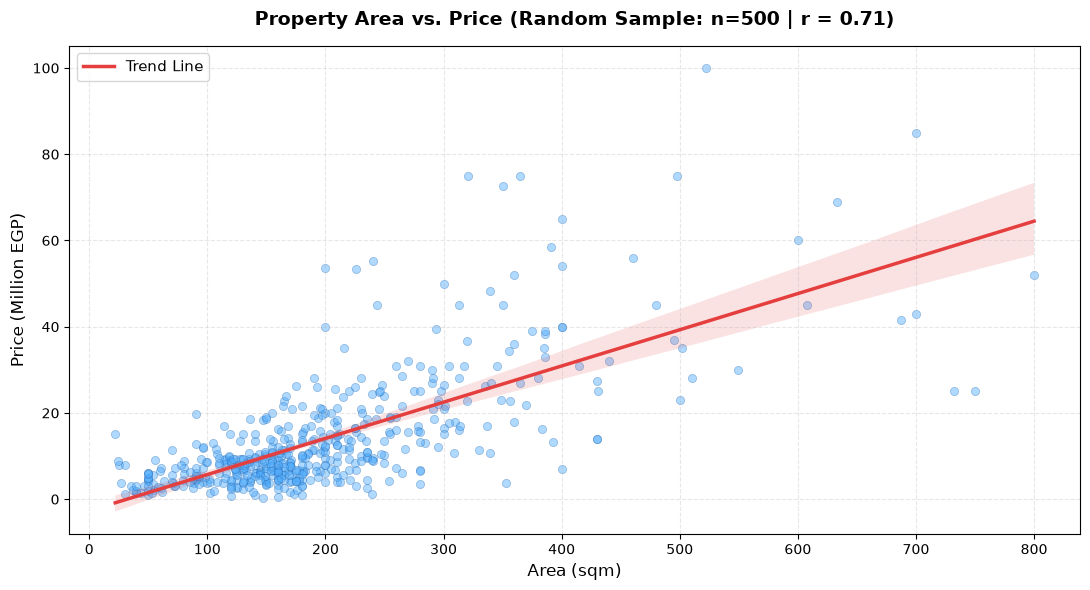

In [11]:
# 1. Filter out extreme top 1% outliers (commercial land / ultra-mansions)
area_cap = dfs['area_value'].quantile(0.99)   # ~950 sqm
price_cap = dfs['price_egp'].quantile(0.99)   # ~111M EGP

filtered_df = dfs[
    (dfs['area_value'] > 0) & (dfs['area_value'] <= area_cap) &
    (dfs['price_egp'] > 0) & (dfs['price_egp'] <= price_cap)
].copy()

filtered_df['price_million'] = filtered_df['price_egp'] / 1e6

# 2. Take a random sample (e.g., 1,500 properties) for a clean, non-crowded scatter plot
sample_size = 500
sampled_df = filtered_df.sample(n=min(sample_size, len(filtered_df)), random_state=42)

# 3. Plot with Seaborn regplot
plt.figure(figsize=(11, 6))

sns.regplot(
    data=sampled_df,
    x='area_value',
    y='price_million',
    scatter_kws={
        'alpha': 0.45,
        'color': '#4facfe',
        's': 35,
        'edgecolor': '#2b6cb0',
        'linewidths': 0.5    # <-- Changed to 'linewidths' (plural)
    },
    line_kws={
        'color': '#e53e3e',
        'linewidth': 2.5,
        'label': 'Trend Line'
    }
)

corr = sampled_df['area_value'].corr(sampled_df['price_million'])

plt.title(f'Property Area vs. Price (Random Sample: n={len(sampled_df):,} | r = {corr:.2f})', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Area (sqm)', fontsize=12)
plt.ylabel('Price (Million EGP)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()



In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. حساب معامل الارتباط المباشر بين المساحة والسعر
area_price_corr = valid_data['area_value'].corr(valid_data['price_egp'])
print(f"Correlation between Area and Price: {area_price_corr:.2f}")

# 2. حساب مصفوفة الارتباط بين كافة المتغيرات الرقمية بعد التنظيف
num_cols = ['price_egp', 'area_value', 'bedrooms', 'bathrooms', 'price_per_sqm']
clean_corr = valid_data[num_cols].corr()

print("\nFull Correlation Matrix with Price:")
print(clean_corr['price_egp'].sort_values(ascending=False))

# 3. رسم مصفوفة الارتباط Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(clean_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix (Filtered Data)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

NameError: name 'valid_data' is not defined

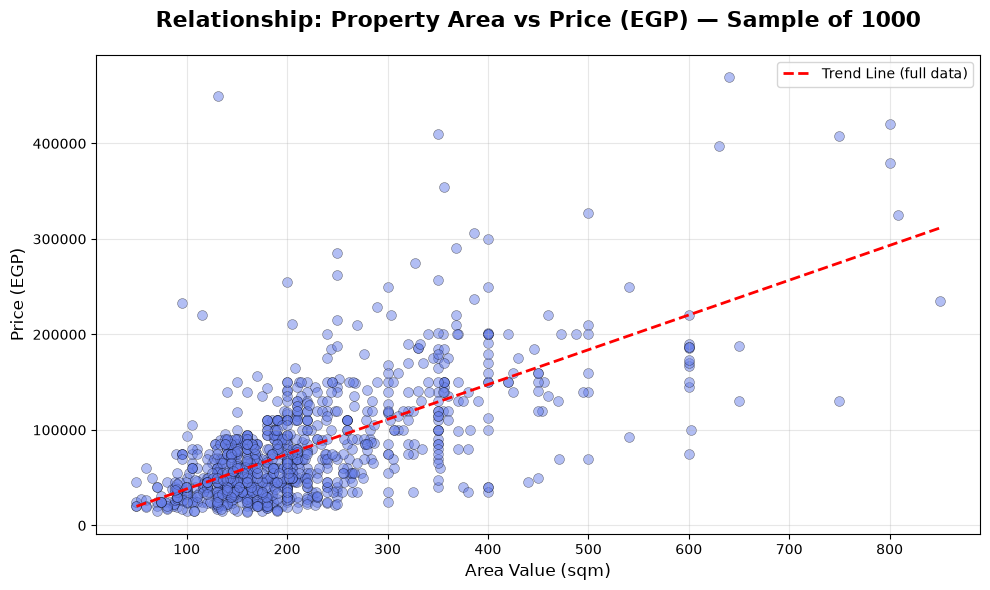

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. تجهيز البيانات وإزالة الفاضي
valid_data = dfr[['area_value', 'price_egp']].dropna()

# 2. إزالة الـ Outliers المتطرفة (أعلى وأقل 1%)
low_area, high_area = valid_data['area_value'].quantile([0.01, 0.99])
low_price, high_price = valid_data['price_egp'].quantile([0.01, 0.99])

filtered = valid_data[
    (valid_data['area_value'].between(low_area, high_area)) &
    (valid_data['price_egp'].between(low_price, high_price))
]

# 3. أخذ عينة عشوائية لتقليل التزاحم (بدل ما نرسم كل النقاط)
sample_size = min(1000, len(filtered))
sampled = filtered.sample(n=sample_size, random_state=42)

x = sampled['area_value']
y = sampled['price_egp']

plt.figure(figsize=(10, 6))
plt.scatter(x, y, c='#667eea', alpha=0.5, s=50, edgecolors='black', linewidth=0.4)

plt.title(f'Relationship: Property Area vs Price (EGP) — Sample of {sample_size}', 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Area Value (sqm)', fontsize=12)
plt.ylabel('Price (EGP)', fontsize=12)
plt.grid(True, alpha=0.3)

# 4. خط الاتجاه محسوب على كل البيانات المفلترة (مش بس العينة) عشان يبقى دقيق
z = np.polyfit(filtered['area_value'], filtered['price_egp'], 1)
p = np.poly1d(z)
x_sorted = np.sort(filtered['area_value'])
plt.plot(x_sorted, p(x_sorted), "r--", linewidth=2, label='Trend Line (full data)')

plt.legend()
plt.tight_layout()
plt.show()

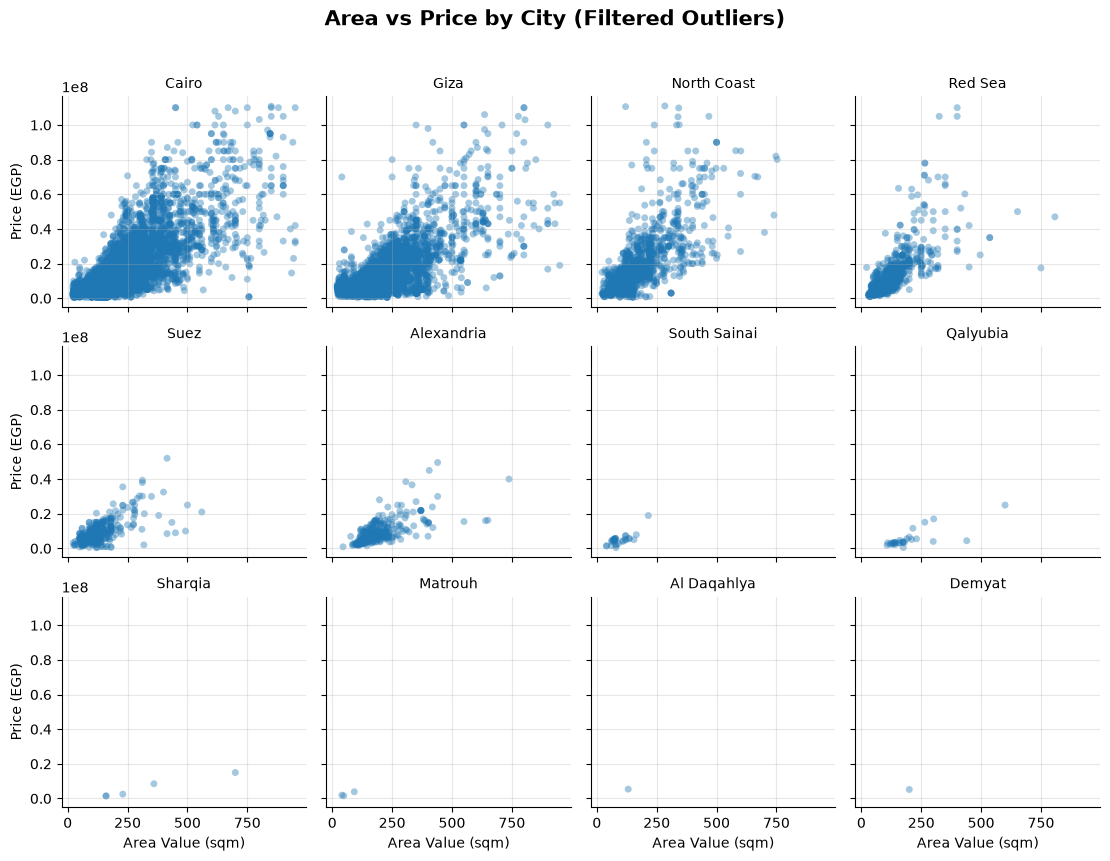

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# 1. تنظيف البيانات من القيم الفارغة والـ Outliers (أعلى 1% متطرف)
clean_df = dfs.dropna(subset=['city', 'area_value', 'price_egp']).copy()

max_area = clean_df['area_value'].quantile(0.99)
max_price = clean_df['price_egp'].quantile(0.99)
filtered_df = clean_df[(clean_df['area_value'] <= max_area) & (clean_df['price_egp'] <= max_price)]

# 2. ترتيب المدن حسب عدد النقاط عشان الأكثر كثافة تظهر الأول
city_order = filtered_df['city'].value_counts().index.tolist()

# 3. Facet grid بدل الرسمة الواحدة المتداخلة
g = sns.relplot(
    data=filtered_df,
    x='area_value',
    y='price_egp',
    col='city',
    col_wrap=4,
    col_order=city_order,
    kind='scatter',
    alpha=0.4,
    s=25,
    edgecolor='none',
    facet_kws={'sharex': True, 'sharey': True},
    height=2.8
)

g.fig.suptitle('Area vs Price by City (Filtered Outliers)', fontsize=15, fontweight='bold', y=1.02)
g.set_axis_labels('Area Value (sqm)', 'Price (EGP)')
g.set_titles('{col_name}')

for ax in g.axes.flat:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


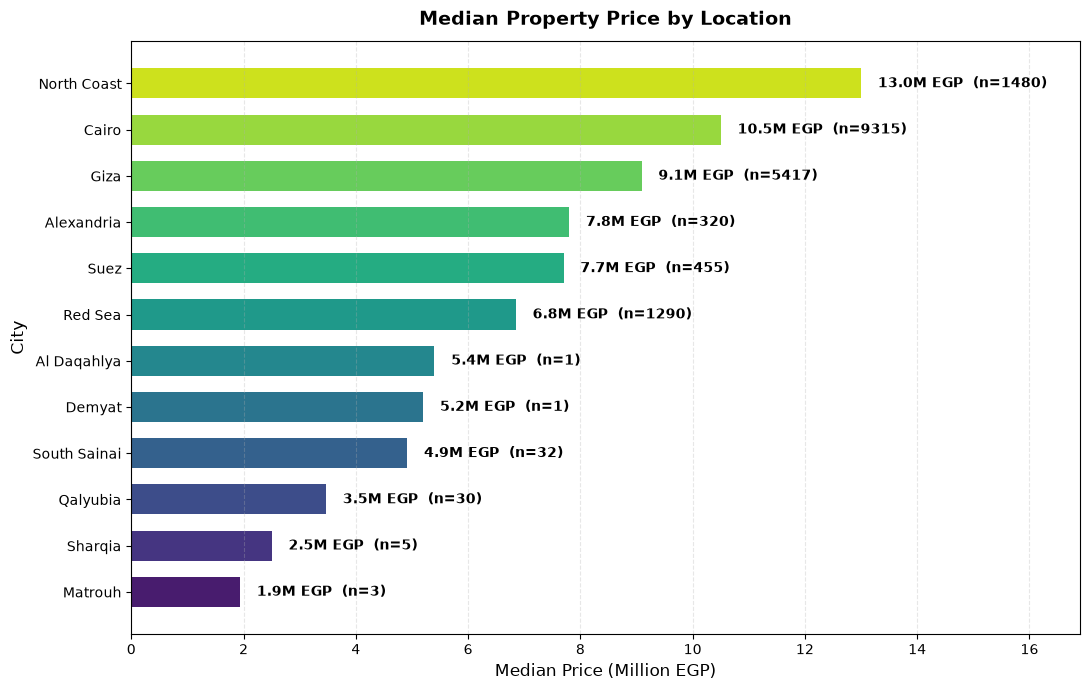

In [ ]:

# Calculate median price in millions and listing count
median_summary = (
    dfs.assign(price_m=dfs['price_egp'] / 1e6)
       .groupby('city')
       .agg(median_price=('price_m', 'median'), count=('price_m', 'count'))
       .sort_values('median_price', ascending=True)
)

plt.figure(figsize=(11, 7))
colors = sns.color_palette('viridis', len(median_summary))
bars = plt.barh(median_summary.index, median_summary['median_price'], color=colors, edgecolor='none', height=0.65)

# Add direct value labels on each bar
for bar, count in zip(bars, median_summary['count']):
    w = bar.get_width()
    plt.text(
        w + 0.3, bar.get_y() + bar.get_height() / 2,
        f'{w:.1f}M EGP  (n={count})',
        va='center', ha='left', fontsize=10, fontweight='bold'
    )

plt.title('Median Property Price by Location', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Median Price (Million EGP)', fontsize=12)
plt.ylabel('City', fontsize=12)
plt.xlim(0, median_summary['median_price'].max() * 1.3)
plt.grid(True, axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


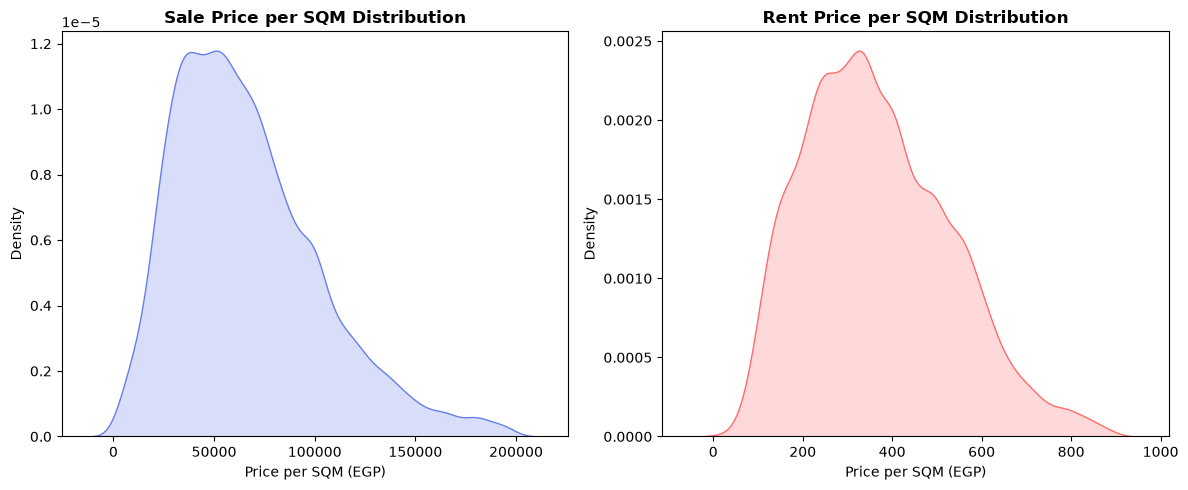

In [ ]:

# 1. حساب سعر المتر المربع لكل DataFrame
dfs['price_per_sqm'] = dfs['price_egp'] / dfs['area_value']
dfr['price_per_sqm'] = dfr['price_egp'] / dfr['area_value']

# 2. استبعاد القيم الفارغة والـ Outliers المتطرفة لتوضيح المنحنى (أقل من الـ Percentile 98)
sale_sqm = dfs['price_per_sqm'][dfs['price_per_sqm'] < dfs['price_per_sqm'].quantile(0.98)].dropna()
rent_sqm = dfr['price_per_sqm'][dfr['price_per_sqm'] < dfr['price_per_sqm'].quantile(0.98)].dropna()

plt.figure(figsize=(12, 5))

# رسم توزيع البيع من dfs
plt.subplot(1, 2, 1)
sns.kdeplot(data=sale_sqm, fill=True, color='#667eea')
plt.title('Sale Price per SQM Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Price per SQM (EGP)')

# رسم توزيع الإيجار من dfr
plt.subplot(1, 2, 2)
sns.kdeplot(data=rent_sqm, fill=True, color='#ff6b6b')
plt.title('Rent Price per SQM Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Price per SQM (EGP)')

plt.tight_layout()
plt.show()

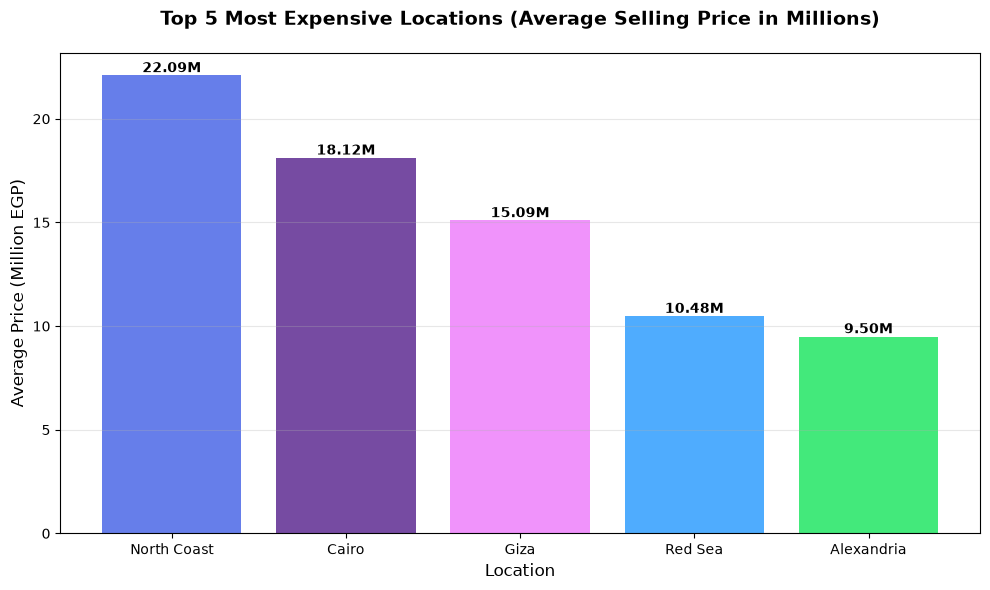

In [ ]:
avg_price_by_loc = dfs.groupby('city')['price_egp'].mean().sort_values(ascending=False).head(5)

plt.figure(figsize=(10, 6))
bars = plt.bar(avg_price_by_loc.index, avg_price_by_loc.values / 1e6, color=['#667eea', '#764ba2', '#f093fb', '#4facfe', '#43e97b'])
plt.title('Top 5 Most Expensive Locations (Average Selling Price in Millions)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Location', fontsize=12)
plt.ylabel('Average Price (Million EGP)', fontsize=12)
plt.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f}M', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

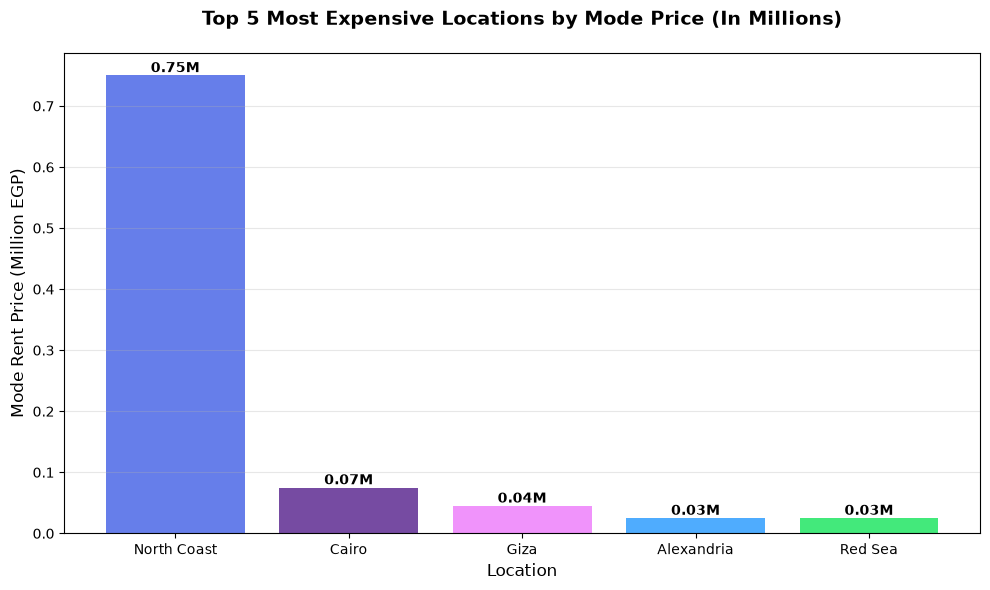

In [ ]:
# 1. Calculate the mode instead of mean
mode_price_by_loc = (
    dfr.groupby('city')['price_egp']
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
    .sort_values(ascending=False)
    .head(5)
)

plt.figure(figsize=(10, 6))
# 2. Plot the mode values
bars = plt.bar(
    mode_price_by_loc.index, 
    mode_price_by_loc.values / 1e6, 
    color=['#667eea', '#764ba2', '#f093fb', '#4facfe', '#43e97b']
)

# 3. Update titles and axis labels to reflect 'Mode'
plt.title('Top 5 Most Expensive Locations by Mode Price (In Millions)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Location', fontsize=12)
plt.ylabel('Mode Rent Price (Million EGP)', fontsize=12)
plt.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2., 
        height,
        f'{height:.2f}M', 
        ha='center', 
        va='bottom', 
        fontsize=10, 
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

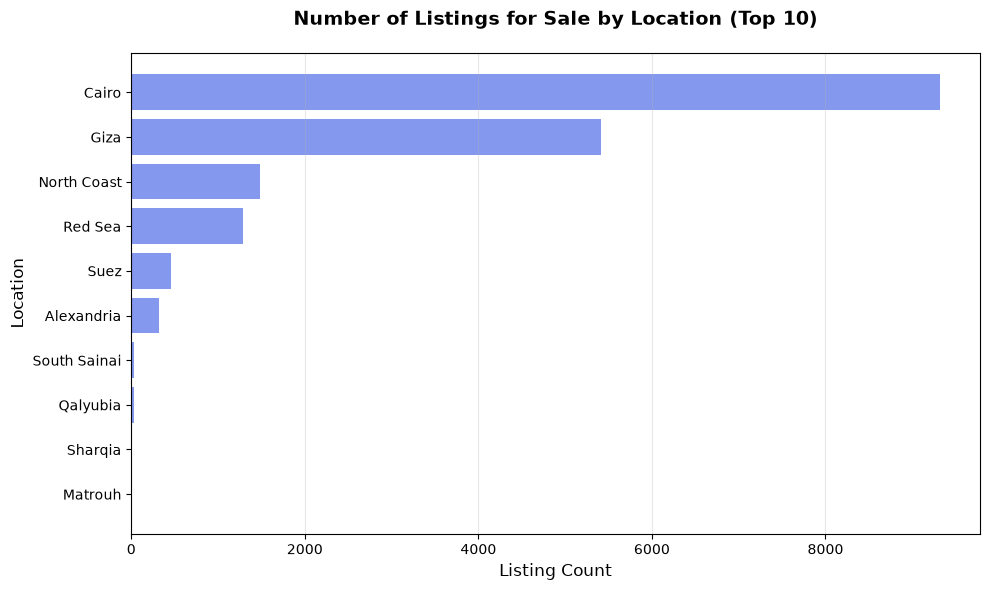

In [ ]:
# عدد الإعلانات لكل منطقة
location_counts = dfs['city'].value_counts().head(10).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(location_counts.index, location_counts.values, color='#667eea', alpha=0.8)
plt.title('Number of Listings for Sale by Location (Top 10)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Listing Count', fontsize=12)
plt.ylabel('Location', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

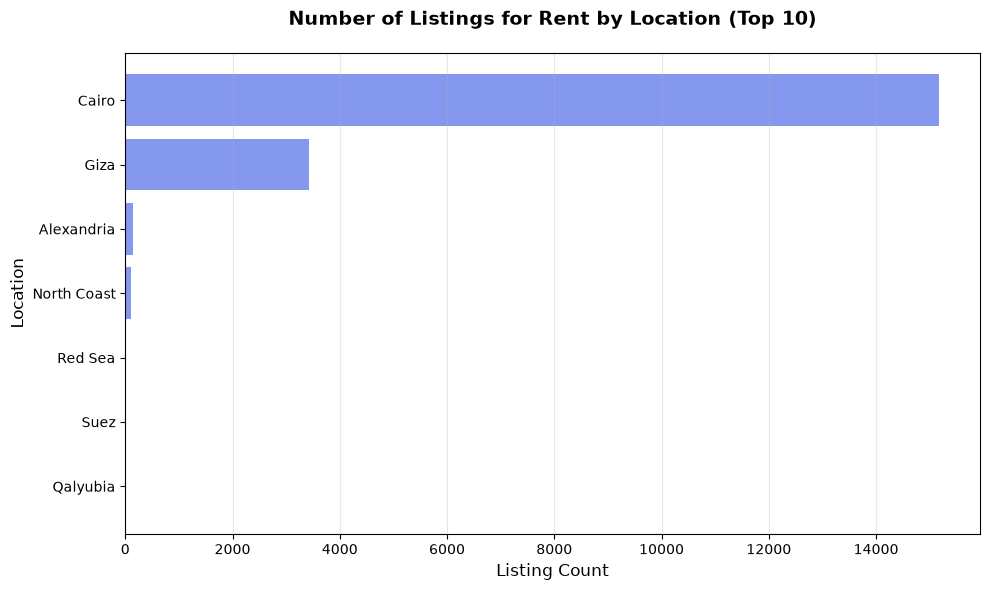

In [ ]:
# عدد الإعلانات لكل منطقة
location_counts = dfr['city'].value_counts().head(10).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(location_counts.index, location_counts.values, color='#667eea', alpha=0.8)
plt.title('Number of Listings for Rent by Location (Top 10)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Listing Count', fontsize=12)
plt.ylabel('Location', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

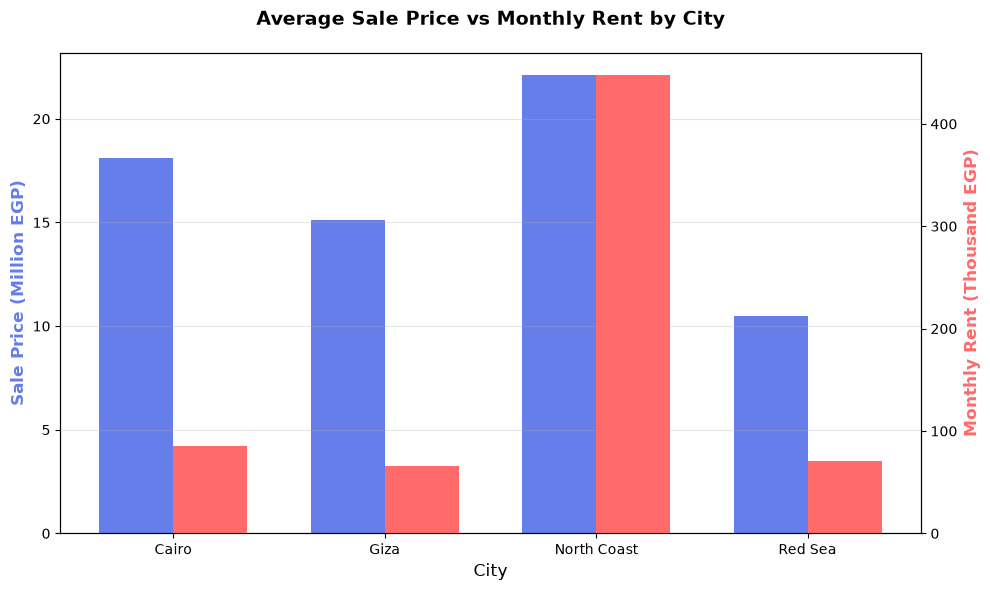

In [ ]:

# 1. اختيار أعلى 4 مدن تكراراً (بناءً على بيانات البيع)
top_cities = dfs['city'].value_counts().head(4).index

# 2. حساب متوسط سعر البيع ومتوسط الإيجار لكل مدينة
sale_avg = dfs[dfs['city'].isin(top_cities)].groupby('city')['price_egp'].mean()
rent_avg = dfr[dfr['city'].isin(top_cities)].groupby('city')['price_egp'].mean()

# 3. دمج المتوسطات في DataFrame واحد مع الحفاظ على الترتيب
plot_data = pd.DataFrame({'Sale': sale_avg, 'Rent': rent_avg}).reindex(top_cities)

# 4. إعداد رسم المحور الثنائي (Dual Axis) بوضوح
x = np.arange(len(top_cities))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()  # محور Y ثانوي للإيجار

# رسم أعمدة البيع (بالمليون) والإيجار (بالألف)
bars_sale = ax1.bar(x - width/2, plot_data['Sale'] / 1e6, width, color='#667eea', label='Avg Sale (Million EGP)')
bars_rent = ax2.bar(x + width/2, plot_data['Rent'] / 1e3, width, color='#ff6b6b', label='Avg Rent (Thousand EGP)')

# الضبط والتنسيق
ax1.set_xlabel('City', fontsize=12)
ax1.set_ylabel('Sale Price (Million EGP)', color='#667eea', fontsize=12, fontweight='bold')
ax2.set_ylabel('Monthly Rent (Thousand EGP)', color='#ff6b6b', fontsize=12, fontweight='bold')

plt.xticks(x, top_cities)
plt.title('Average Sale Price vs Monthly Rent by City', fontsize=14, fontweight='bold', pad=20)
ax1.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

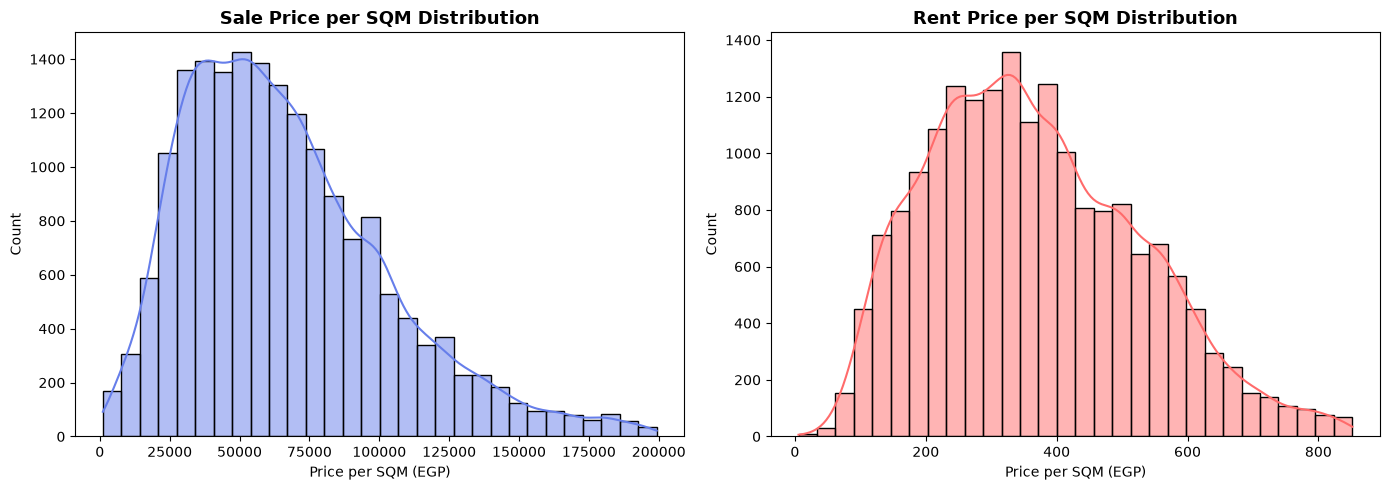

In [ ]:

# حساب سعر المتر
dfs['price_per_sqm'] = dfs['price_egp'] / dfs['area_value']
dfr['price_per_sqm'] = dfr['price_egp'] / dfr['area_value']

# استبعاد القيم الشاذة المتطرفة للرسم فقط (أقل من الـ Percentile 99)
sale_clean = dfs['price_per_sqm'][dfs['price_per_sqm'] < dfs['price_per_sqm'].quantile(0.98)].dropna()
rent_clean = dfr['price_per_sqm'][dfr['price_per_sqm'] < dfr['price_per_sqm'].quantile(0.98)].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. رسم توزيع سعر المتر للبيع
sns.histplot(sale_clean, bins=30, kde=True, ax=axes[0], color='#667eea')
axes[0].set_title('Sale Price per SQM Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price per SQM (EGP)')
axes[0].set_ylabel('Count')

# 2. رسم توزيع سعر المتر للإيجار
sns.histplot(rent_clean, bins=30, kde=True, ax=axes[1], color='#ff6b6b')
axes[1].set_title('Rent Price per SQM Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Price per SQM (EGP)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [ ]:
dfr['price_per_sqm']=dfr['price_egp']/dfr['area_value']

In [ ]:
dfr.info()

<class 'pandas.DataFrame'>
Index: 18866 entries, 0 to 18916
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  18866 non-null  str    
 1   title          18866 non-null  str    
 2   price_egp      18866 non-null  float64
 3   city           18866 non-null  str    
 4   town           18866 non-null  str    
 5   district       18866 non-null  str    
 6   lat            18866 non-null  float64
 7   lon            18866 non-null  float64
 8   bedrooms       18863 non-null  str    
 9   bathrooms      18866 non-null  str    
 10  area_value     18866 non-null  float64
 11  furnished      18759 non-null  str    
 12  listing_level  18866 non-null  str    
 13  listed_date    18866 non-null  str    
 14  description    18866 non-null  str    
 15  agent_id       18866 non-null  int64  
 16  broker_id      18866 non-null  int64  
 17  price_per_sqm  18866 non-null  float64
dtypes: float64(5), int64(2

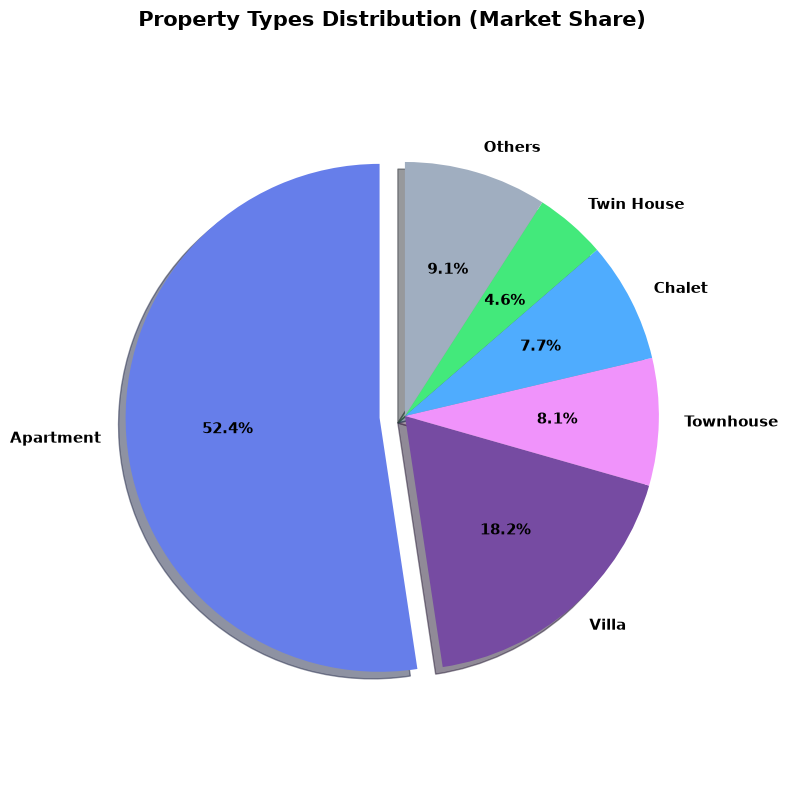

In [ ]:
type_counts = dfs['property_type'].value_counts()

top5 = type_counts.head(5)
others_sum = type_counts.iloc[5:].sum()

if others_sum > 0:
    top5['Others'] = others_sum

labels = top5.index
sizes = top5.values
colors = ['#667eea', '#764ba2', '#f093fb', '#4facfe', '#43e97b', '#a0aec0']  # extra color for Others
explode = [0.1] + [0] * (len(labels) - 1)  # إبراز الشريحة الأولى فقط

plt.figure(figsize=(8, 8))
plt.pie(sizes, explode=explode, labels=labels, colors=colors[:len(labels)], autopct='%1.1f%%',
        shadow=True, startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'})

plt.title('Property Types Distribution (Market Share)', fontsize=15, fontweight='bold', pad=20)
plt.axis('equal')
plt.tight_layout()
plt.show()


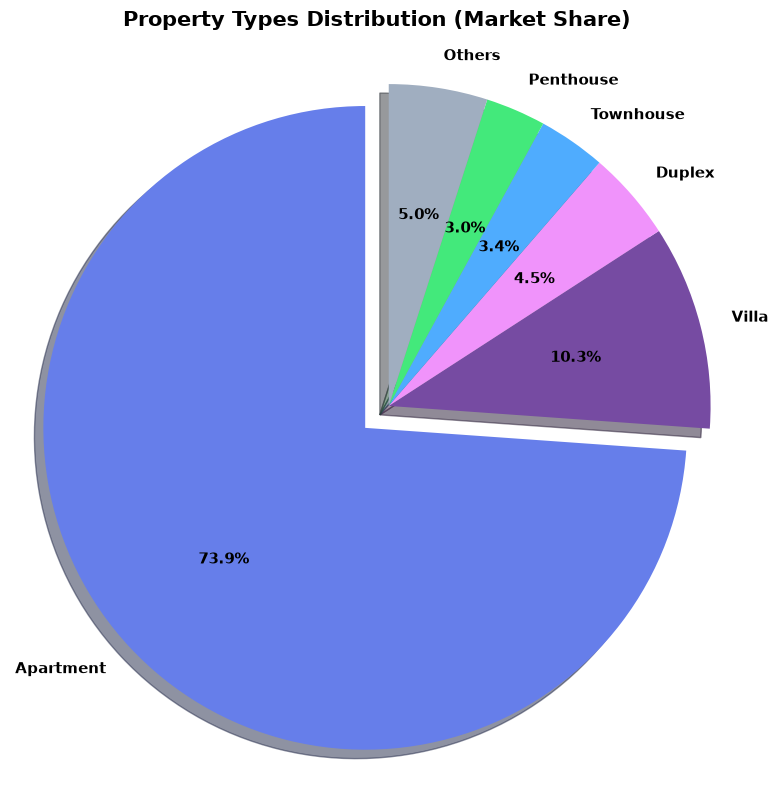

In [ ]:
# حساب عدد العقارات لكل نوع (Top 5 + الباقي كـ Others)
type_counts = dfr['property_type'].value_counts()

top5 = type_counts.head(5)
others_sum = type_counts.iloc[5:].sum()

if others_sum > 0:
    top5['Others'] = others_sum

labels = top5.index
sizes = top5.values
colors = ['#667eea', '#764ba2', '#f093fb', '#4facfe', '#43e97b', '#a0aec0']  # لون إضافي لـ Others
explode = [0.1] + [0] * (len(labels) - 1)  # إبراز الشريحة الأولى فقط

plt.figure(figsize=(8, 8))
plt.pie(sizes, explode=explode, labels=labels, colors=colors[:len(labels)], autopct='%1.1f%%',
        shadow=True, startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'})

plt.title('Property Types Distribution (Market Share)', fontsize=15, fontweight='bold', pad=20)
plt.axis('equal')
plt.tight_layout()
plt.show()

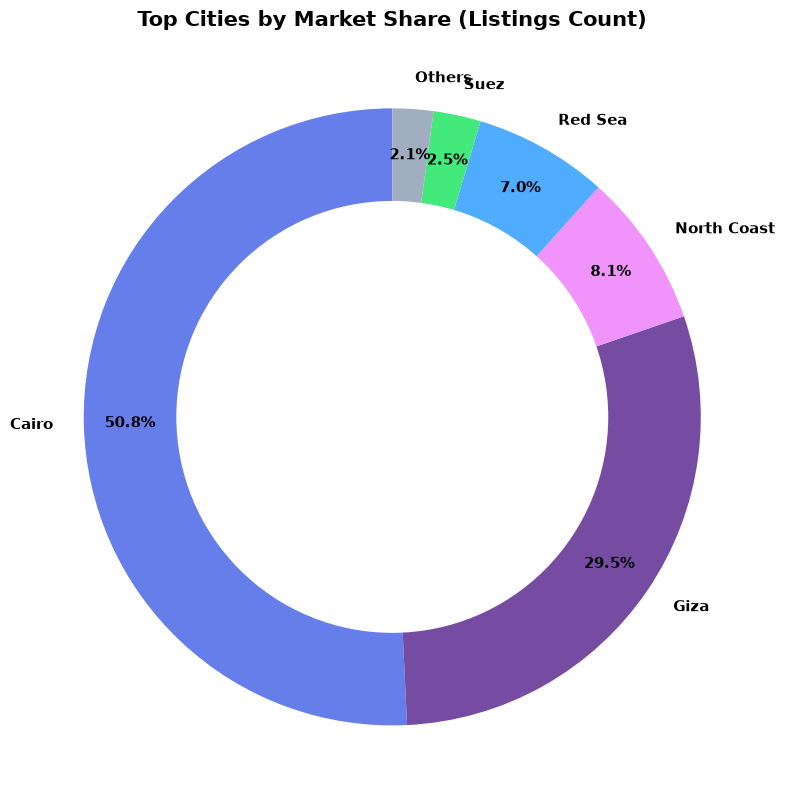

In [ ]:
city_counts = dfs['city'].value_counts()

top5 = city_counts.head(5)
others_sum = city_counts.iloc[5:].sum()

if others_sum > 0:
    top5['Others'] = others_sum

labels = top5.index
sizes = top5.values
colors = ['#667eea', '#764ba2', '#f093fb', '#4facfe', '#43e97b', '#a0aec0']  # لون إضافي لـ Others

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(sizes, labels=labels, colors=colors[:len(labels)], autopct='%1.1f%%',
       startangle=90, pctdistance=0.85, textprops={'fontsize': 11, 'fontweight': 'bold'})

# رسم الدائرة البيضاء في المنتصف لتحويلها لـ Donut Chart
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

ax.set_title('Top Cities by Market Share (Listings Count)', fontsize=15, fontweight='bold', pad=20)
ax.axis('equal')
plt.tight_layout()
plt.show()

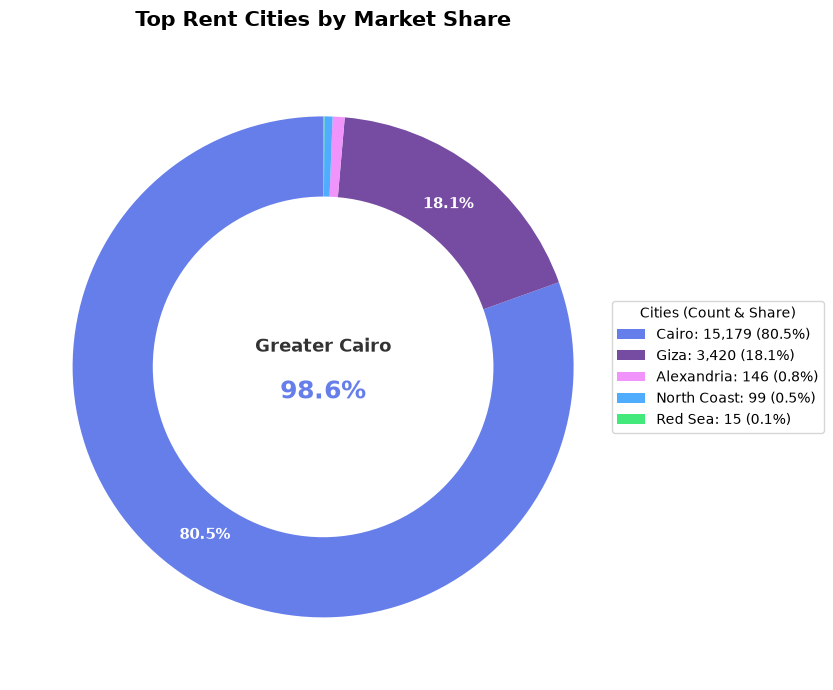

In [ ]:
import matplotlib.pyplot as plt

# 1. Top 5 cities
city_counts = dfr['city'].value_counts().head(5)
total_listings = dfr['city'].count()

colors = ['#667eea', '#764ba2', '#f093fb', '#4facfe', '#43e97b']

fig, ax = plt.subplots(figsize=(9, 7))

# 2. Only show percentage on slices >= 5% to avoid text collision
wedges, texts, autotexts = ax.pie(
    city_counts.values,
    colors=colors,
    autopct=lambda pct: f'{pct:.1f}%' if pct >= 5 else '',
    pctdistance=0.82,
    startangle=90,
    textprops={'fontsize': 11, 'fontweight': 'bold', 'color': 'white'}
)

# 3. Donut center circle
centre_circle = plt.Circle((0, 0), 0.68, fc='white')
ax.add_artist(centre_circle)

# Center text: Greater Cairo Market Share
cairo_share = (city_counts['Cairo'] + city_counts['Giza']) / total_listings * 100
ax.text(0, 0.08, 'Greater Cairo', ha='center', va='center', fontsize=13, fontweight='bold', color='#333333')
ax.text(0, -0.10, f'{cairo_share:.1f}%', ha='center', va='center', fontsize=18, fontweight='bold', color='#667eea')

# 4. Clean side legend with Count & Percentage
legend_labels = [f'{city}: {count:,} ({count/total_listings*100:.1f}%)' for city, count in city_counts.items()]
ax.legend(wedges, legend_labels, title='Cities (Count & Share)', loc='center left', bbox_to_anchor=(0.95, 0.5), fontsize=10)

ax.set_title('Top Rent Cities by Market Share', fontsize=15, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()


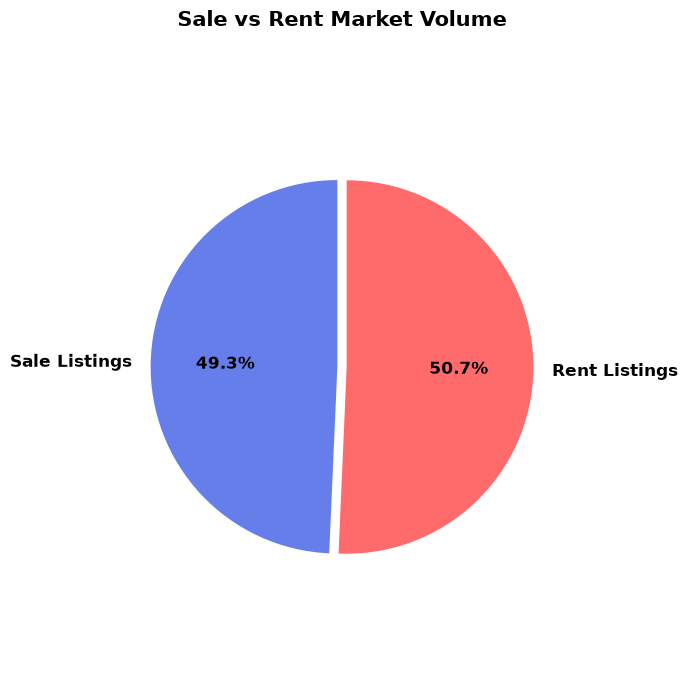

In [ ]:
# حساب إجمالي عدد الإعلانات في كل ملف
sizes = [len(dfs), len(dfr)]
labels = ['Sale Listings', 'Rent Listings']
colors = ['#667eea', '#ff6b6b']

plt.figure(figsize=(7, 7))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%',
        explode=(0.05, 0), startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})

plt.title('Sale vs Rent Market Volume', fontsize=15, fontweight='bold', pad=20)
plt.axis('equal')
plt.tight_layout()
plt.show()

In [ ]:

import plotly.express as px
# 1. Select common columns and label categories
common_cols = ['lat', 'lon', 'property_type', 'city', 'area_value', 'bedrooms', 'bathrooms', 'price_egp']

df_sell = dfs[common_cols].dropna(subset=['lat', 'lon']).copy()
df_sell['category'] = 'Buy'
df_sell['display_price'] = (df_sell['price_egp'] / 1e6).round(2).astype(str) + ' M EGP'

df_rent = dfr[common_cols].dropna(subset=['lat', 'lon']).copy()
df_rent['category'] = 'Rent'
df_rent['display_price'] = df_rent['price_egp'].apply(lambda x: f'{x:,.0f} EGP/mo')

# 2. Sample 2,500 from each set (5,000 total) for fast, smooth rendering
df_geo = pd.concat([
    df_sell.sample(n=min(2500, len(df_sell)), random_state=42),
    df_rent.sample(n=min(2500, len(df_rent)), random_state=42)
], ignore_index=True)

# 3. Create interactive map
fig = px.scatter_map(
    df_geo,
    lat="lat", 
    lon="lon",
    color="category",
    color_discrete_map={'Buy': '#1f77b4', 'Rent': '#ff4d4f'},
    hover_name="property_type",
    hover_data={
        "category": True,
        "city": True,
        "display_price": True,
        "area_value": True,
        "bedrooms": True,
        "bathrooms": True,
        "lat": False,
        "lon": False
    },
    zoom=6,
    height=650,
    title="Geospatial Distribution: Buy vs. Rent Properties in Egypt"
)

fig.update_layout(
    map_style="open-street-map",
    margin={"r": 0, "t": 40, "l": 0, "b": 0}
)
fig.show()
